Original Dataset:
   Feature_1  Feature_2  True_Label
0   0.658801  -0.355963           1
1   1.986302  -0.133490           1
2  -0.111623   0.455081           1
3   0.905008   0.266798           0
4   1.181619  -0.494965           1

Dataset Shape: (300, 3)

Number of Clusters: 2
Number of Noise Points: 0

Clustered Dataset:
   Feature_1  Feature_2  True_Label  Cluster
0   0.658801  -0.355963           1        0
1   1.986302  -0.133490           1        0
2  -0.111623   0.455081           1        0
3   0.905008   0.266798           0        1
4   1.181619  -0.494965           1        0

Points in Each Cluster:
Cluster
0    150
1    150
Name: count, dtype: int64


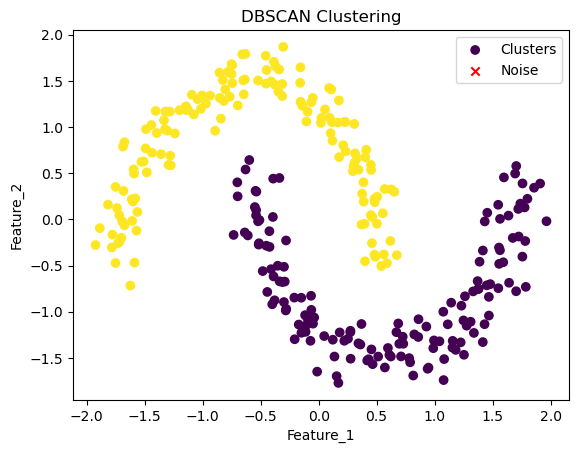

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

df = pd.read_csv(r"C:\Users\Tanuja\Downloads\make_moons.csv")

df.columns = df.columns.astype(str).str.strip()

print("Original Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

numeric_data = df.select_dtypes(include="number")

remove_columns = [
    col for col in numeric_data.columns
    if col.strip().lower().replace("_", "").replace(" ", "")
    in ["id", "index", "label", "class", "target", "cluster",
        "output", "groundtruth", "unnamed:0"]
]

X = numeric_data.drop(columns=remove_columns)

if X.shape[1] < 2:
    raise ValueError("Dataset must contain at least two numerical features.")

X = X.iloc[:, :2]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

df["Cluster"] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

print("\nClustered Dataset:")
print(df.head())

print("\nPoints in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

plt.scatter(X_scaled[labels != -1, 0],
            X_scaled[labels != -1, 1],
            c=labels[labels != -1], cmap="viridis",
            label="Clusters")

plt.scatter(X_scaled[labels == -1, 0],
            X_scaled[labels == -1, 1],
            color="red", marker="x", label="Noise")

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("DBSCAN Clustering")
plt.legend()
plt.show()

In [ ]:

%pip install pandas matplotlib scikit-learn
# PRACTICAL 9: DBSCAN CLUSTERING

## 1. Aim

To employ a density-based clustering algorithm, DBSCAN, on a suitable open-access dataset to identify the clustering structure and noise points.

## 2. Dataset Used

**Dataset Name:** Make Moons Dataset  
**File Name:** `make_moons.csv`  
**File Path:** `C:\Users\Tanuja\Downloads\make_moons.csv`

The Make Moons dataset is a synthetic dataset containing two moon-shaped groups of data points. It is useful for demonstrating density-based clustering because DBSCAN can identify irregularly shaped clusters.

The program selects two numerical features for clustering. Any recognized ID, index, target, class or label columns are excluded.

## 3. Theory

### What is Clustering?

Clustering is an unsupervised machine learning technique used to divide data points into groups called clusters.

Data points within the same cluster have similar characteristics, while points in different clusters have different characteristics.

Clustering does not require predefined class labels. It discovers patterns and groups from the input data.

### What is DBSCAN?

DBSCAN stands for **Density-Based Spatial Clustering of Applications with Noise**.

It is an unsupervised machine learning algorithm that groups data points based on their density.

Unlike K-Means, DBSCAN does not require the number of clusters to be specified in advance. It identifies dense regions as clusters and points in low-density regions as noise or outliers.

DBSCAN can identify clusters with irregular shapes, making it suitable for datasets such as Make Moons.

### Important Terms in DBSCAN

**1. Epsilon (eps)**

Epsilon is the maximum distance between two points for them to be considered neighbours.

In this practical:

`eps = 0.3`

It means that points within a distance of 0.3 in the scaled feature space are considered neighbours.

**2. Min_samples**

Min_samples specifies the minimum number of points required within the epsilon neighbourhood for a point to be considered a core point.

In this practical:

`min_samples = 5`

It means that at least five points, including the point itself, must be present in its epsilon neighbourhood for it to qualify as a core point.

**3. Core Point**

A core point has at least Min_samples points within its epsilon neighbourhood, including itself.

**4. Border Point**

A border point does not have enough neighbouring points to be a core point, but it lies within the neighbourhood of a core point.

**5. Noise Point**

A noise point is neither a core point nor a border point. It does not belong to any cluster.

In Scikit-learn, noise points are assigned the label `-1`.

### Types of Points in DBSCAN

| Point Type | Description |
|---|---|
| Core Point | Has at least Min_samples points in its epsilon neighbourhood |
| Border Point | Lies within the neighbourhood of a core point but does not have enough neighbours to be a core point |
| Noise Point | Does not belong to any cluster |

### Working of DBSCAN Algorithm

1. Select a data point from the dataset.
2. Find all neighbouring points within the specified epsilon distance.
3. Check whether the number of neighbouring points satisfies Min_samples.
4. If the condition is satisfied, identify the point as a core point and create a cluster.
5. Expand the cluster by adding density-reachable neighbouring points.
6. If a point is not a core point but is reachable from a core point, it can become a border point.
7. Points that cannot be assigned to any cluster are marked as noise.
8. Repeat the process until all data points have been processed.

### Distance Calculation

DBSCAN commonly uses Euclidean distance to identify neighbouring points.

The Euclidean distance between two points is:

d(p, q) = √[(p₁ − q₁)² + (p₂ − q₂)²]

Where:

- p and q represent two data points.
- p₁ and q₁ represent their first feature values.
- p₂ and q₂ represent their second feature values.

If the distance between two points is less than or equal to eps, they are considered neighbours.

### Importance of Feature Scaling

Feature scaling is important because DBSCAN uses distance calculations to identify neighbouring points.

If features have different numerical ranges, a feature with a larger range may dominate the distance calculation.

StandardScaler transforms the data using:

z = (x − μ) / σ

Where:

- x = Original feature value.
- μ = Mean of the feature.
- σ = Standard deviation of the feature.
- z = Standardized value.

After scaling, each feature has approximately zero mean and unit variance.

### Advantages of DBSCAN

1. It does not require the number of clusters in advance.
2. It can identify clusters with irregular shapes.
3. It can detect noise and outliers.
4. It works well when clusters are separated by low-density regions.
5. It does not require random centroid initialization.

### Limitations of DBSCAN

1. Selecting suitable eps and Min_samples values can be difficult.
2. It may perform poorly when clusters have significantly different densities.
3. It is sensitive to feature scaling.
4. Results can be affected by the choice of distance metric.
5. It may become less effective in high-dimensional datasets.

## 4. Algorithm

1. Import the required Python libraries: Pandas, Matplotlib, StandardScaler and DBSCAN.
2. Load the Make Moons CSV dataset.
3. Remove unnecessary spaces from the column names.
4. Display the first five records and dataset shape.
5. Select the numerical columns from the dataset.
6. Remove recognized ID, index, target, class and label columns.
7. Select the first two remaining numerical features.
8. Apply StandardScaler to standardize the selected features.
9. Initialize the DBSCAN algorithm with eps = 0.3 and min_samples = 5.
10. Apply DBSCAN to the scaled data and obtain cluster labels.
11. Add cluster labels to the original dataset.
12. Calculate the number of clusters and noise points.
13. Display the clustered dataset and cluster distribution.
14. Visualize the clusters and noise points using a scatter plot.

## 5. Python Program

### Installation command

Run only if the required libraries are not installed:

```python
%pip install pandas matplotlib scikit-learn
```

### Main Program

```python
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

df = pd.read_csv(r"C:\Users\Tanuja\Downloads\make_moons.csv")

df.columns = df.columns.astype(str).str.strip()

print("Original Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

numeric_data = df.select_dtypes(include="number")

remove_columns = [
    col for col in numeric_data.columns
    if col.strip().lower().replace("_", "").replace(" ", "")
    in ["id", "index", "label", "class", "target", "cluster",
        "output", "groundtruth", "unnamed:0"]
]

X = numeric_data.drop(columns=remove_columns)

if X.shape[1] < 2:
    raise ValueError("Dataset must contain at least two numerical features.")

X = X.iloc[:, :2]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

df["Cluster"] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

print("\nClustered Dataset:")
print(df.head())

print("\nPoints in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

plt.scatter(X_scaled[labels != -1, 0],
            X_scaled[labels != -1, 1],
            c=labels[labels != -1], cmap="viridis",
            label="Clusters")

plt.scatter(X_scaled[labels == -1, 0],
            X_scaled[labels == -1, 1],
            color="red", marker="x", label="Noise")

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("DBSCAN Clustering")
plt.legend()
plt.show()
```

## 6. Line-by-Line Explanation of the Program

### A. Importing Libraries

**Line 1:**
```python
import pandas as pd
```
Imports the Pandas library with the alias `pd`. It is used to load and manipulate the dataset.

**Line 2:**
```python
import matplotlib.pyplot as plt
```
Imports Matplotlib's plotting module with the alias `plt`. It is used to visualize the clusters and noise points.

**Line 3:**
```python
from sklearn.preprocessing import StandardScaler
```
Imports StandardScaler from Scikit-learn. It is used to standardize the numerical input features.

**Line 4:**
```python
from sklearn.cluster import DBSCAN
```
Imports the DBSCAN algorithm from Scikit-learn. It is used to perform density-based clustering.

### B. Loading the Dataset

**Line 5:**
```python
df = pd.read_csv(r"C:\Users\Tanuja\Downloads\make_moons.csv")
```
Loads the Make Moons CSV file into a Pandas DataFrame named `df`.

The letter `r` creates a raw string, allowing Windows backslashes in the file path to be used safely.

**Line 6:**
```python
df.columns = df.columns.astype(str).str.strip()
```
Converts column names into strings and removes unnecessary spaces from their beginning and end.

**Line 7:**
```python
print("Original Dataset:")
```
Displays a heading before printing the dataset.

**Line 8:**
```python
print(df.head())
```
Displays the first five records of the dataset.

**Line 9:**
```python
print("\nDataset Shape:", df.shape)
```
Displays the number of rows and columns in the dataset.

The `shape` attribute returns the dataset dimensions.

### C. Selecting Numerical Features

**Line 10:**
```python
numeric_data = df.select_dtypes(include="number")
```
Selects only numerical columns from the original dataset.

Categorical columns are not selected because DBSCAN performs distance calculations on numerical features.

**Lines 11–17:**
```python
remove_columns = [
    col for col in numeric_data.columns
    if col.strip().lower().replace("_", "").replace(" ", "")
    in ["id", "index", "label", "class", "target", "cluster",
        "output", "groundtruth", "unnamed:0"]
]
```

This code creates a list of numerical columns that should be excluded from clustering.

- `numeric_data.columns` accesses the numerical column names.
- `col.strip()` removes extra spaces.
- `lower()` converts the column name into lowercase.
- `replace("_", "")` removes underscores.
- `replace(" ", "")` removes spaces.
- The `in` operator checks whether the cleaned name matches any recognized ID or target column name.

The purpose is to avoid using identification numbers or known class labels as clustering features.

**Line 18:**
```python
X = numeric_data.drop(columns=remove_columns)
```
Removes the identified columns from the numerical dataset and stores the remaining columns in `X`.

**Lines 19–20:**
```python
if X.shape[1] < 2:
    raise ValueError("Dataset must contain at least two numerical features.")
```
Checks whether at least two numerical features remain.

If fewer than two features are available, the program displays an error because the selected implementation requires two features for its scatter plot.

**Line 21:**
```python
X = X.iloc[:, :2]
```
Selects the first two remaining numerical columns.

These two columns are used as input features for DBSCAN.

### D. Feature Scaling

**Line 22:**
```python
scaler = StandardScaler()
```
Creates an object of the StandardScaler class.

**Line 23:**
```python
X_scaled = scaler.fit_transform(X)
```
Calculates the mean and standard deviation of each selected feature and transforms the values into a standardized scale.

This helps DBSCAN calculate distances without one feature dominating due to its numerical range.

### E. Applying DBSCAN

**Line 24:**
```python
dbscan = DBSCAN(eps=0.3, min_samples=5)
```
Creates a DBSCAN model with two important parameters.

- `eps=0.3` specifies the maximum neighbourhood distance between points in the scaled feature space.
- `min_samples=5` specifies the minimum number of points required in an epsilon neighbourhood for a point to be considered a core point.

**Line 25:**
```python
labels = dbscan.fit_predict(X_scaled)
```
Fits the DBSCAN model to the scaled dataset and assigns a cluster label to each data point.

The labels are stored in the variable `labels`.

A label of `-1` represents a noise point.

### F. Adding Cluster Labels

**Line 26:**
```python
df["Cluster"] = labels
```
Adds a new column named `Cluster` to the original dataset.

The column contains the cluster number assigned to each data point. Noise points receive the label `-1`.

### G. Counting Clusters and Noise Points

**Line 27:**
```python
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
```
Calculates the total number of clusters without counting noise points.

- `set(labels)` finds the unique cluster labels.
- `len()` counts the unique labels.
- `if -1 in labels` checks whether noise points exist.
- If `-1` exists, one is subtracted because noise is not a cluster.

**Line 28:**
```python
n_noise = list(labels).count(-1)
```
Counts the number of data points assigned the label `-1`.

These points are treated as noise or outliers by DBSCAN.

**Line 29:**
```python
print("\nNumber of Clusters:", n_clusters)
```
Displays the number of clusters identified by DBSCAN.

**Line 30:**
```python
print("Number of Noise Points:", n_noise)
```
Displays the total number of noise points detected.

### H. Displaying Clustered Dataset

**Line 31:**
```python
print("\nClustered Dataset:")
```
Displays a heading for the clustered dataset.

**Line 32:**
```python
print(df.head())
```
Displays the first five records along with the newly added Cluster column.

**Line 33:**
```python
print("\nPoints in Each Cluster:")
```
Displays a heading before showing the number of points in each cluster.

**Line 34:**
```python
print(df["Cluster"].value_counts().sort_index())
```
Counts the number of points assigned to each cluster and sorts the cluster labels in ascending order.

If noise points exist, the output also contains the count for cluster label `-1`.

### I. Visualizing Clusters and Noise Points

**Lines 35–38:**
```python
plt.scatter(X_scaled[labels != -1, 0],
            X_scaled[labels != -1, 1],
            c=labels[labels != -1], cmap="viridis",
            label="Clusters")
```
Creates a scatter plot of points that belong to clusters.

- `labels != -1` selects points that are not noise.
- `X_scaled[labels != -1, 0]` selects their first feature values.
- `X_scaled[labels != -1, 1]` selects their second feature values.
- `c=labels[labels != -1]` assigns colours according to cluster labels.
- `cmap="viridis"` selects the colour map.
- `label="Clusters"` provides a legend label.

**Lines 39–41:**
```python
plt.scatter(X_scaled[labels == -1, 0],
            X_scaled[labels == -1, 1],
            color="red", marker="x", label="Noise")
```
Displays noise points separately from the clusters.

- `labels == -1` selects only noise points.
- `color="red"` displays them in red.
- `marker="x"` uses an X-shaped marker.
- `label="Noise"` adds a legend label.

**Line 42:**
```python
plt.xlabel(X.columns[0])
```
Sets the X-axis label using the name of the first selected feature.

**Line 43:**
```python
plt.ylabel(X.columns[1])
```
Sets the Y-axis label using the name of the second selected feature.

**Line 44:**
```python
plt.title("DBSCAN Clustering")
```
Sets the title of the scatter plot.

**Line 45:**
```python
plt.legend()
```
Displays the legend to distinguish clusters from noise points.

**Line 46:**
```python
plt.show()
```
Displays the final clustering graph.

## 7. Expected Output

The program displays:

1. The first five rows of the original dataset.
2. The shape of the dataset.
3. The number of clusters identified by DBSCAN.
4. The number of noise points detected.
5. The first five records with their cluster labels.
6. The number of points in each cluster.
7. A scatter plot showing clusters and noise points separately.

**Note:** The exact number of clusters and noise points depends on the actual CSV data and the selected DBSCAN parameters. Do not assume fixed output values before running the program.

## 8. Important Viva Questions and Answers

**Q1. What is DBSCAN?**

DBSCAN is a density-based unsupervised clustering algorithm that groups closely packed data points and identifies noise points.

**Q2. What is the full form of DBSCAN?**

Density-Based Spatial Clustering of Applications with Noise.

**Q3. Is DBSCAN supervised or unsupervised?**

DBSCAN is an unsupervised machine learning algorithm.

**Q4. What is eps in DBSCAN?**

Eps specifies the maximum distance within which two points are considered neighbours.

**Q5. What is min_samples?**

It specifies the minimum number of points required in an epsilon neighbourhood for a point to be considered a core point.

**Q6. What is a core point?**

A core point has at least the required number of neighbouring points within its epsilon distance.

**Q7. What is a border point?**

A border point is not a core point but lies within the neighbourhood of a core point.

**Q8. What is a noise point?**

A noise point is a data point that does not belong to any cluster.

**Q9. What is the noise label in Scikit-learn DBSCAN?**

The noise label is `-1`.

**Q10. Does DBSCAN require the number of clusters in advance?**

No. DBSCAN automatically identifies clusters based on the density of the data points.

**Q11. Why is StandardScaler used?**

It standardizes features so that differences in their numerical ranges do not dominate distance calculations.

**Q12. What is the use of fit_predict()?**

It fits the DBSCAN model and returns a cluster label for each data point.

**Q13. Can DBSCAN detect outliers?**

Yes. It identifies points that do not belong to any dense region and marks them as noise.

**Q14. Can DBSCAN identify irregularly shaped clusters?**

Yes. It can identify clusters of different shapes, provided they are separated by regions of sufficiently low density.

**Q15. What happens if eps is too small?**

Many points may be classified as noise because too few neighbouring points fall within the selected distance.

**Q16. What happens if eps is too large?**

Different clusters may merge into one large cluster, reducing the ability to identify separate groups.

## 9. Advanced External Viva Questions

**Q1. What is the difference between K-Means and DBSCAN?**

| K-Means | DBSCAN |
|---|---|
| Centroid-based clustering | Density-based clustering |
| Requires K in advance | Does not require K in advance |
| Sensitive to outliers | Can identify noise points |
| Uses cluster centroids | Uses density and neighbourhoods |
| Works best for compact, roughly spherical clusters | Can identify irregularly shaped clusters |

**Q2. What is density reachability?**

A point is density-reachable from another point when it can be reached through a sequence of neighbouring points that satisfy DBSCAN's density conditions.

**Q3. What is the difference between eps and min_samples?**

Eps defines the neighbourhood distance, whereas min_samples defines the minimum number of points needed within that neighbourhood to form a core point.

**Q4. Can DBSCAN work without feature scaling?**

It can, but when features have different numerical ranges, distance calculations may become biased. Therefore, feature scaling is generally recommended.

**Q5. What happens if the dataset has clusters with different densities?**

A single eps and min_samples combination may not identify all clusters properly. Some clusters may be merged, while others may be marked as noise.

**Q6. Why is DBSCAN suitable for the Make Moons dataset?**

The Make Moons dataset contains curved, moon-shaped groups. DBSCAN can identify irregularly shaped clusters, unlike basic centroid-based clustering methods such as K-Means.

**Q7. Can DBSCAN produce only one cluster?**

Yes. If the selected eps is large enough, many data points may be connected into a single cluster.

**Q8. Can DBSCAN classify every point into a cluster?**

No. Some points may be classified as noise and assigned the label `-1`.

## 10. Dataset-Specific Viva Questions

**Q1. What is the Make Moons dataset?**

It is a synthetic dataset containing two interleaving moon-shaped groups of data points. It is commonly used to demonstrate clustering and classification algorithms.

**Q2. Why is the Make Moons dataset suitable for DBSCAN?**

It contains non-linear, curved structures that are useful for demonstrating DBSCAN's ability to identify irregularly shaped clusters.

**Q3. Why are two features selected?**

Two features are selected to perform clustering and visualize the results in a two-dimensional scatter plot.

**Q4. Why are target or class columns removed?**

Clustering is an unsupervised technique. Using predefined target labels as input would provide information about the expected groups and could distort the clustering experiment.

**Q5. What does the noise count represent?**

It represents the number of points that DBSCAN could not assign to any cluster.

## 11. Practical Coding Questions

**Q1. Which library is used to load the dataset?**

Pandas.

**Q2. Which library provides DBSCAN?**

Scikit-learn.

**Q3. Which function is used to scale the features?**

`fit_transform()` with StandardScaler.

**Q4. Which function applies DBSCAN and returns labels?**

`fit_predict()`.

**Q5. Which command counts the noise points?**

`list(labels).count(-1)`.

**Q6. Which command displays the number of clusters?**

`n_clusters`.

**Q7. What does `value_counts()` do?**

It counts the number of records belonging to each cluster label.

**Q8. Which function is used to draw the scatter plot?**

`plt.scatter()`.

**Q9. What does `labels == -1` mean?**

It selects all points identified as noise.

**Q10. What does `plt.legend()` do?**

It displays the legend that identifies the clusters and noise points.

## 12. Important Points to Remember for Viva

- Algorithm: DBSCAN.
- Full form: Density-Based Spatial Clustering of Applications with Noise.
- Learning type: Unsupervised Learning.
- Dataset: Make Moons.
- Main parameters: eps and min_samples.
- eps used in this program: 0.3.
- min_samples used in this program: 5.
- Feature scaling: StandardScaler.
- Core point: Has the required number of neighbours.
- Border point: Lies within the neighbourhood of a core point but does not satisfy the core-point condition itself.
- Noise point: Point that does not belong to any cluster.
- Noise label in Scikit-learn: -1.
- Distance measure: Euclidean distance by default.
- Final output: Cluster labels, noise-point count and scatter plot.